# Axiom3Sixty Lead Analysis (Synthetic Data)

This notebook builds the database from `sql/schema.sql` and `sql/seed_synthetic.sql`, then answers the questions the sales team asks. Every lead here is generated, so the numbers show the method, not the company's real results.

In [1]:
import sys
sys.path.insert(0, '..')
import matplotlib.pyplot as plt
import pandas as pd
from src.run_queries import build_db, run_all

con = build_db()
q = run_all(con)
pd.read_sql_query('SELECT * FROM leads LIMIT 5', con)

,lead_id,full_name,email,phone,street,city,zip,plan_id,style_id,source,status,submitted_at,first_contacted_at,assigned_user_id
0,1,Quentin Yarbrough,quentin.yarbrough61@example.com,(480) 555-0195,9027 E Desert Lark Ave,San Tan Valley,85140,2,4.0,property_check,contacted,2026-01-01 07:04:00,2026-01-01 14:26:46,4
1,2,Wesley Zeller,wesley.zeller39@example.com,(480) 555-0128,8681 E Saguaro Bloom Way,Tempe,85281,3,1.0,custom_design,won,2026-01-03 05:19:00,2026-01-03 16:49:22,4
2,3,Hector Valdez,hector.valdez89@example.com,(480) 555-0167,4059 E Ocotillo Shadow Dr,Scottsdale,85251,5,2.0,property_check,won,2026-01-03 10:40:00,2026-01-03 14:58:37,2
3,4,Talia Delgado,talia.delgado72@example.com,(480) 555-0192,7335 E Sunstone Trail,San Tan Valley,85140,5,NaN,property_check,contacted,2026-01-04 10:17:00,2026-01-04 16:00:16,3
4,5,Nadia Yarbrough,nadia.yarbrough72@example.com,NaN,9053 E Saguaro Bloom Way,Phoenix,85016,6,4.0,property_check,won,2026-01-06 02:25:00,2026-01-06 17:42:55,4


## 1. Where demand comes from

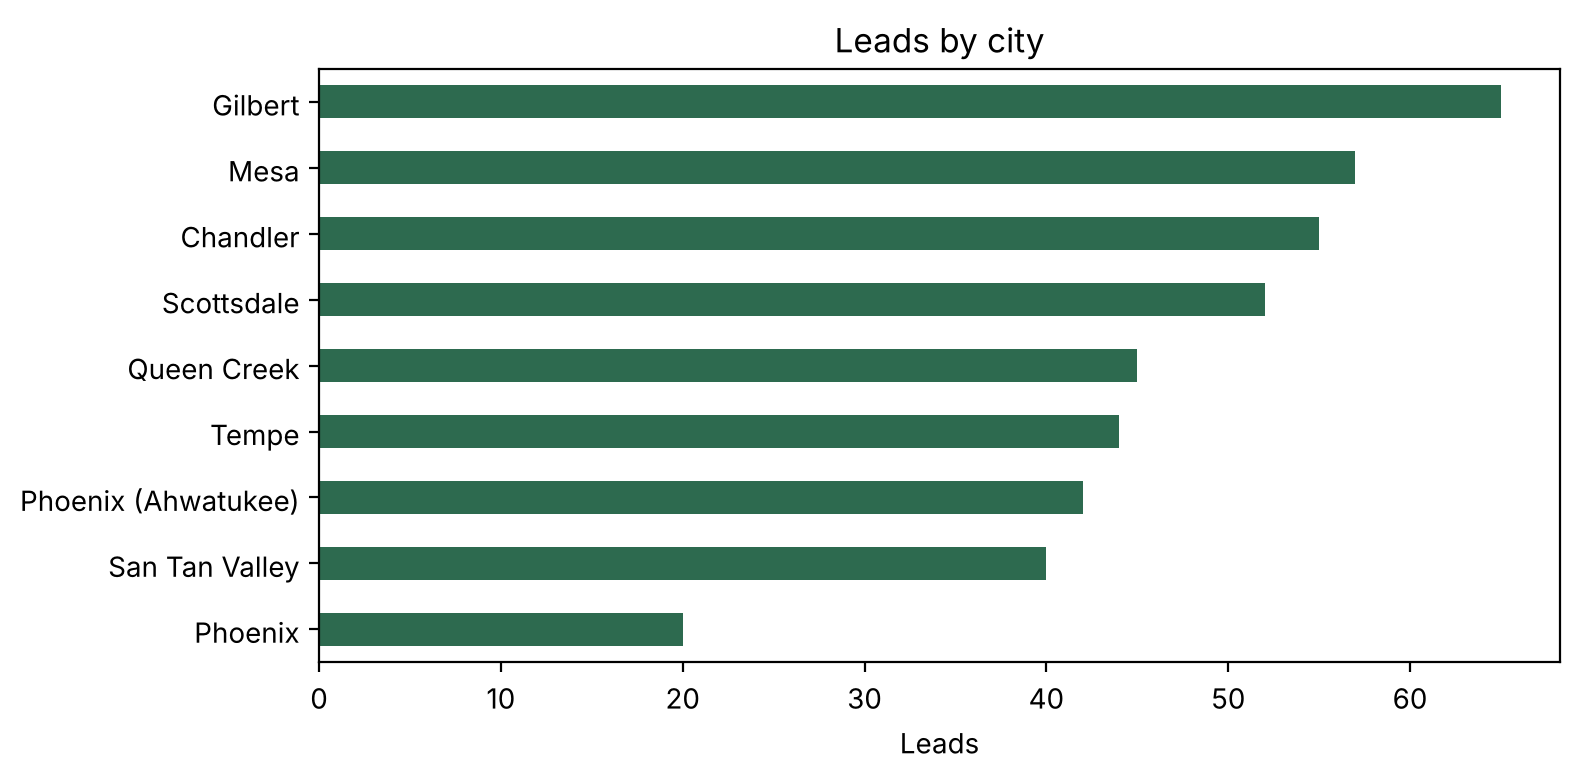

In [2]:
df = q['leads_by_city']
ax = df.plot.barh(x='city', y='leads', legend=False, color='#2D6A4F', figsize=(8, 4))
ax.invert_yaxis(); ax.set_xlabel('Leads'); ax.set_ylabel(''); ax.set_title('Leads by city')
plt.tight_layout()

## 2. Plan demand and open pipeline

In [3]:
q['plan_demand_and_pipeline_value']

,plan_name,base_price,leads,won,open_pipeline_value
0,Casa Luna,195000,94,8,7215000
1,Casa Reina,180000,90,10,3780000
2,Casa Lunita,160000,64,7,4160000
3,Casa Mia,145000,45,3,1885000
4,Casa Reinita,170000,43,6,2380000
5,Casa Mio,150000,38,4,1800000


## 3. The funnel

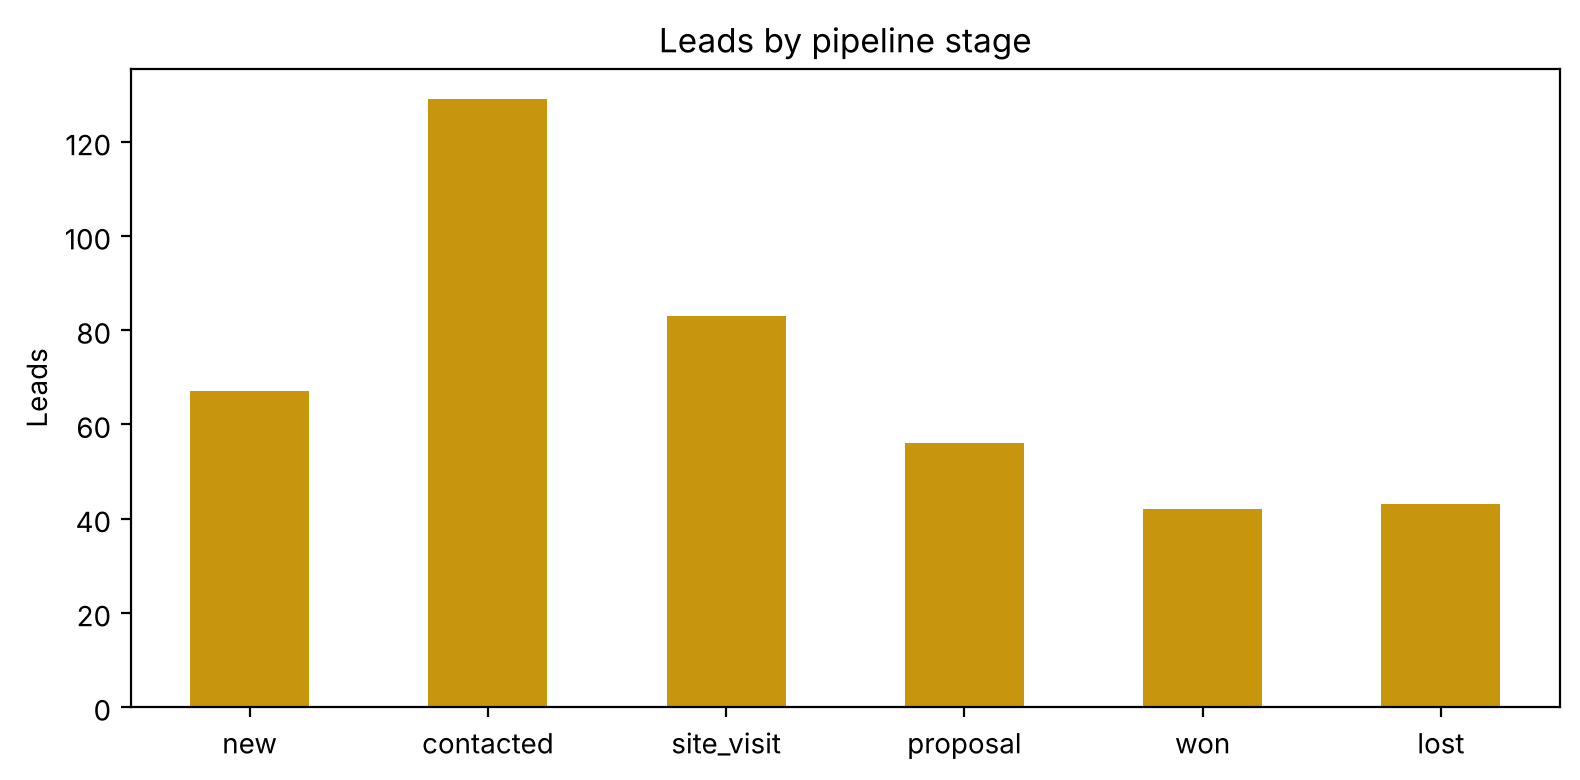

In [4]:
df = q['funnel']
ax = df.plot.bar(x='status', y='leads', legend=False, color='#C8960C', figsize=(8, 4), rot=0)
ax.set_ylabel('Leads'); ax.set_xlabel(''); ax.set_title('Leads by pipeline stage')
plt.tight_layout()

## 4. Speed to lead

Median hours to first contact: 12.7
Share contacted within 24 hours: 76%


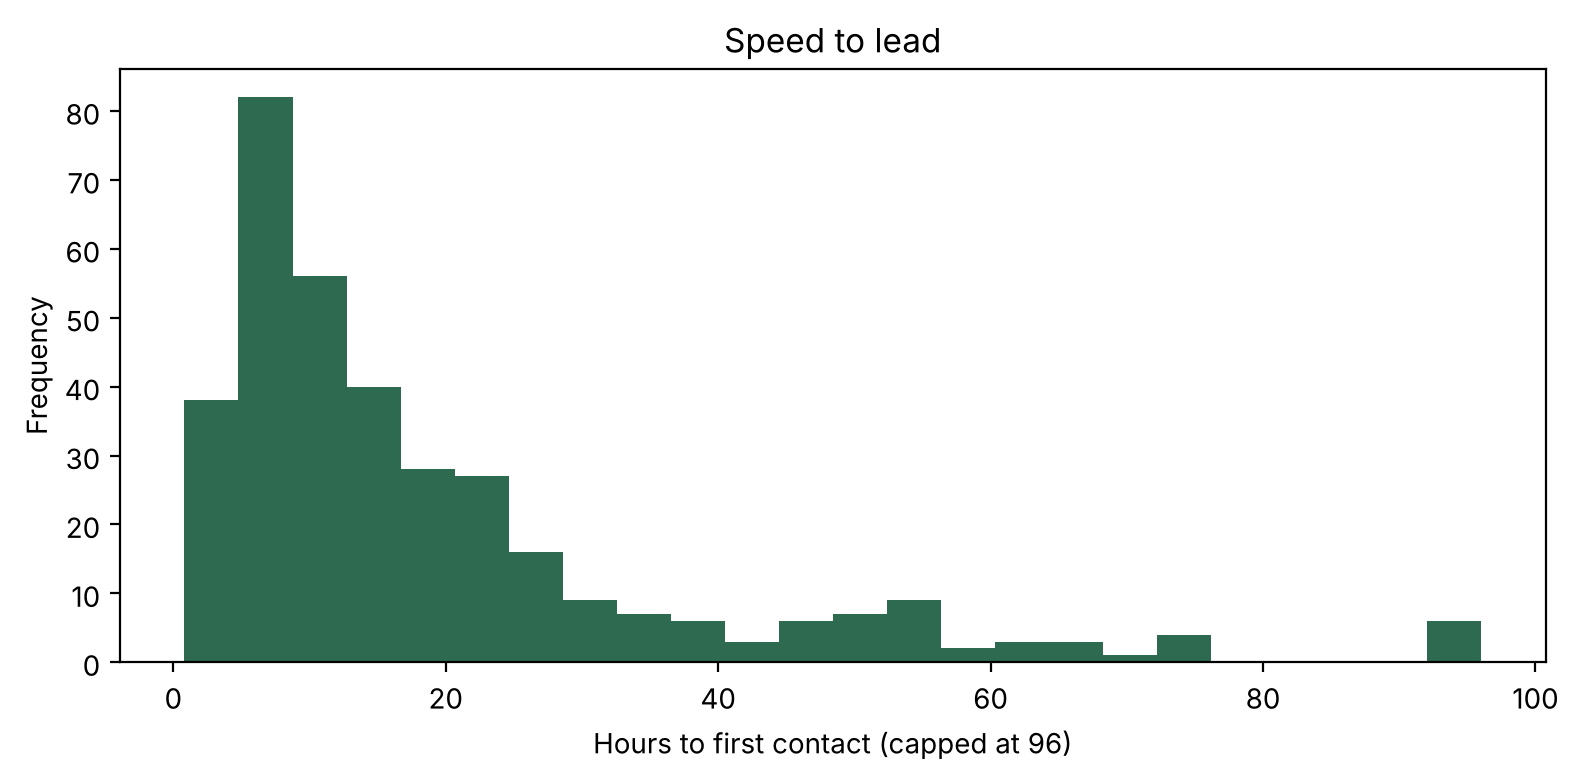

In [5]:
leads = pd.read_sql_query('SELECT submitted_at, first_contacted_at FROM leads WHERE first_contacted_at IS NOT NULL', con, parse_dates=['submitted_at', 'first_contacted_at'])
hours = (leads.first_contacted_at - leads.submitted_at).dt.total_seconds() / 3600
print(f'Median hours to first contact: {hours.median():.1f}')
print(f'Share contacted within 24 hours: {(hours <= 24).mean():.0%}')
ax = hours.clip(upper=96).plot.hist(bins=24, color='#2D6A4F', figsize=(8, 4))
ax.set_xlabel('Hours to first contact (capped at 96)'); ax.set_title('Speed to lead')
plt.tight_layout()

In [6]:
q['speed_to_lead_by_agent']

,agent,leads_contacted,avg_hours_to_contact,within_24h
0,Monique Okafor,114,19.1,86
1,Hannah Hargrove,125,19.6,94
2,Renata Whitaker,114,20.5,88


## 5. Seasonality and render cache

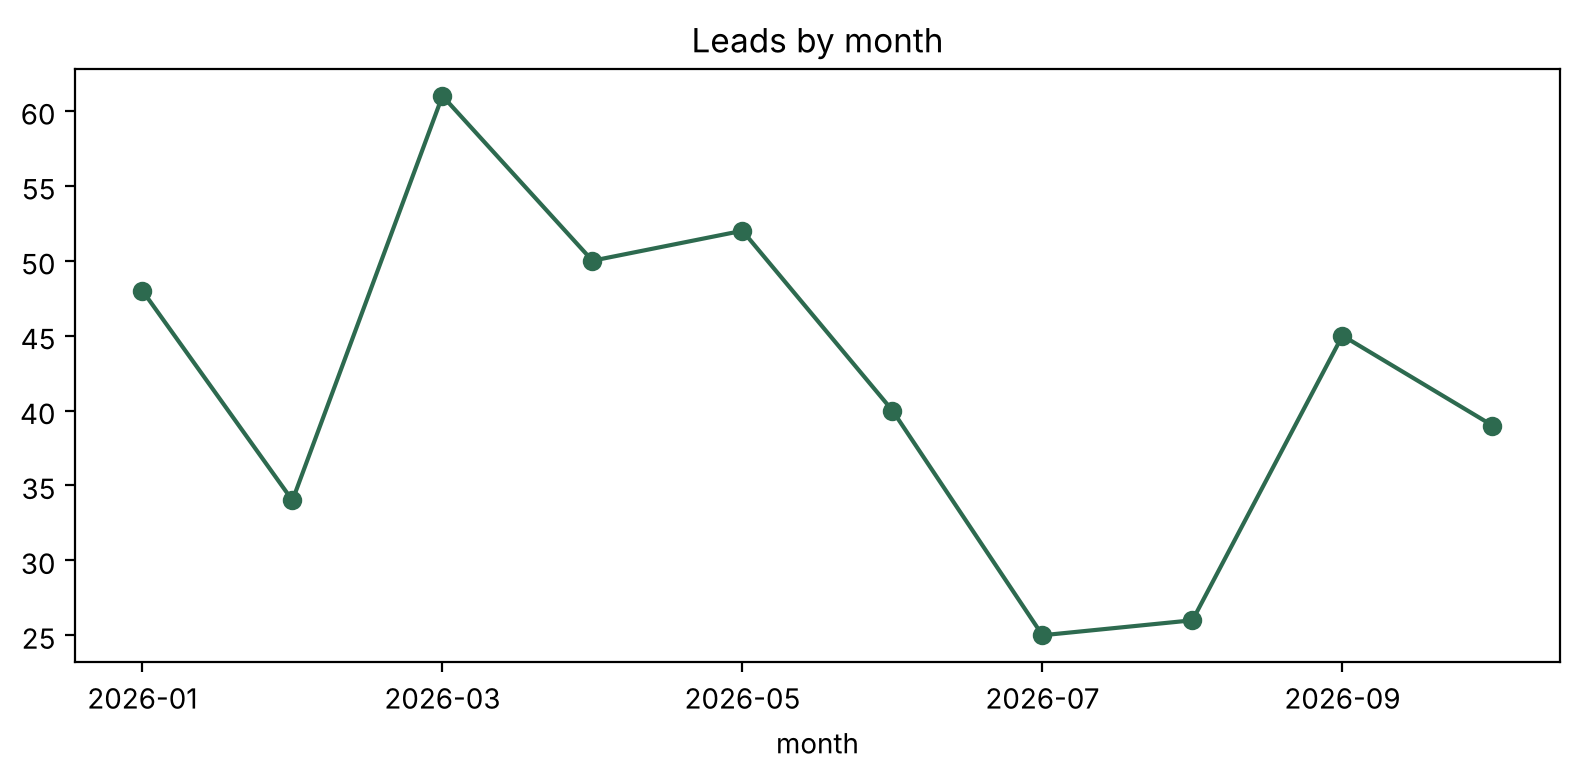

In [7]:
q['monthly_leads'].plot(x='month', y='leads', marker='o', legend=False, color='#2D6A4F', figsize=(8, 4), title='Leads by month')
plt.tight_layout()

In [8]:
q['render_cache_coverage']

,plan_name,cached,possible,coverage_pct
0,Casa Mia,16,20,80.0
1,Casa Mio,15,20,75.0
2,Casa Lunita,15,20,75.0
3,Casa Reina,12,20,60.0
4,Casa Luna,12,20,60.0
5,Casa Reinita,8,20,40.0


## Takeaways

1. The SQL answers every pipeline question from one schema: demand by city, plan, stage, source, and agent.
2. Speed to lead is measurable because the schema stores both submission and first contact times and forbids contact before submission.
3. The render cache table shows which plan, style, and view combinations still need images, so the team can pre generate the gaps before a marketing push.